# Siniestros viales en Bogotá: ¿podemos anticipar los más graves?
**Proyecto Final DataXperience · Etapas 1 y 2**

- **Etapa 1:** selección, exploración y limpieza
- **Etapa 2:** estadística descriptiva, atípicos e hipótesis

**Periodo analizado:** 1 de junio de 2025 al 1 de junio de 2026 (ambos días incluidos).
**Fuente:** Secretaría Distrital de Movilidad de Bogotá (servicio SIMUR / datos abiertos).

> **Cómo ejecutarlo:** *Entorno de ejecución → Ejecutar todo*. Cuando lo pida, sube los 4 CSV originales (`siniestros.csv`, `victimas_lesionadas.csv`, `victimas_fallecidas.csv`, `actores_viales.csv`).

## Etapa 1 · Selección, exploración y limpieza

### 1.1 Justificación del dataset
Elegimos los siniestros viales de Bogotá porque son datos públicos, reales y de nuestra ciudad, con variables numéricas, categóricas y de fecha. Como futuros ingenieros de sistemas, este análisis muestra cómo convertir datos crudos en decisiones, la misma lógica que aplicamos en nuestros trabajos.

**Pregunta de negocio:** ¿dónde, cuándo y en qué condiciones ocurren los siniestros más graves en Bogotá, y podemos predecir si un siniestro tendrá personas fallecidas?

**Qué tablas usamos y por qué:** `siniestros.csv` tiene una fila por siniestro y es la tabla principal. `victimas_lesionadas.csv` y `victimas_fallecidas.csv` tienen una fila por víctima y se enlazan con el siniestro por **FORMULARIO** (no traen `CODIGO_ACCIDENTE`); por eso **se cuentan por siniestro antes de unirlas** (así no se duplican siniestros). `actores_viales.csv` sirve para el tipo de usuario vial. Las demás tablas descargadas (causas, vehículos, vías) no se necesitan para estas dos etapas.

In [1]:
import os, re, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)

# ===== CONFIGURACIÓN (lo único que podrías cambiar) =====
INICIO = "2025-06-01"                 # primer día incluido
FIN = "2026-06-01"                    # último día incluido
CARPETA_ORIGINALES = "datos/original"
CARPETA_SALIDA = "datos"
ARCHIVOS = {
    "siniestros": "siniestros.csv",
    "lesionados": "victimas_lesionadas.csv",
    "fallecidos": "victimas_fallecidas.csv",
    "actores": "actores_viales.csv",
}

os.makedirs(CARPETA_ORIGINALES, exist_ok=True)
os.makedirs(CARPETA_SALIDA, exist_ok=True)

def faltantes():
    return [f for f in ARCHIVOS.values() if not os.path.exists(os.path.join(CARPETA_ORIGINALES, f))]

if faltantes():
    try:
        from google.colab import files
        print("Sube estos archivos (puedes elegir varios a la vez):", faltantes())
        subidos = files.upload()
        for nombre, contenido in subidos.items():
            with open(os.path.join(CARPETA_ORIGINALES, nombre), "wb") as f:
                f.write(contenido)
    except ImportError:
        pass

if faltantes():
    raise FileNotFoundError(f"Faltan estos archivos en {CARPETA_ORIGINALES}/: {faltantes()}")
print("Archivos encontrados.")

Sube estos archivos (puedes elegir varios a la vez): ['siniestros.csv', 'victimas_lesionadas.csv', 'victimas_fallecidas.csv', 'actores_viales.csv']


Saving actores_viales.csv to actores_viales.csv
Saving victimas_lesionadas.csv to victimas_lesionadas.csv
Saving victimas_fallecidas.csv to victimas_fallecidas.csv
Saving siniestros.csv to siniestros.csv
Archivos encontrados.


### 1.2 Carga y exploración inicial (datos originales, todos los años)

In [2]:
def leer(clave):
    return pd.read_csv(os.path.join(CARPETA_ORIGINALES, ARCHIVOS[clave]), encoding="utf-8-sig", low_memory=False)

sin_raw = leer("siniestros")
les_raw = leer("lesionados")
fal_raw = leer("fallecidos")
act_raw = leer("actores")

for nombre, d in [("siniestros", sin_raw), ("victimas_lesionadas", les_raw),
                  ("victimas_fallecidas", fal_raw), ("actores_viales", act_raw)]:
    print(f"{nombre:22s} filas={d.shape[0]:>8,}  columnas={d.shape[1]}")

sin_raw.head()

siniestros             filas= 147,923  columnas=23
victimas_lesionadas    filas= 144,105  columnas=17
victimas_fallecidas    filas=   4,022  columnas=19
actores_viales         filas= 330,573  columnas=15


,OBJECTID,FORMULARIO,CODIGO_ACCIDENTE,FECHA_OCURRENCIA_ACC,HORA_OCURRENCIA_ACC,ANO_OCURRENCIA_ACC,MES_OCURRENCIA_ACC,DIA_OCURRENCIA_ACC,DIRECCION,GRAVEDAD,CLASE_ACC,LOCALIDAD,MUNICIPIO,FECHA_HORA_ACC,LATITUD,LONGITUD,CIV,PK_CALZADA,BARRIO,MVINOMBRE,DISTANCIA_VIA,LONGITUD_GEOM,LATITUD_GEOM
0,72,A001235561,10532176.0,1607731200000,21:22:00,2020.0,DICIEMBRE,SABADO,CL 20 39 BIS 02,CON MUERTOS,CHOQUE,PUENTE ARANDA,BOGOTA DC,1607808120000,4.626000,-74.094000,16000396.0,520914.0,ORTEZAL,AVENIDA DE LAS AMERICAS,4.3,-74.094000,4.626000
1,351,A001236358,10530794.0,1609200000000,18:10:00,2020.0,DICIEMBRE,MARTES,CL 11 SUR POR KR 5,SOLO DANOS,CHOQUE,SAN CRISTOBAL,BOGOTA DC,1609265400000,4.577634,-74.085276,4000336.0,200944.0,SANTA ANA SUR,AVENIDA FUCHA,0.0,-74.085276,4.577634
2,4882,A001180858,10519181.0,1598832000000,19:00:00,2020.0,AGOSTO,LUNES,KR 7A-CL 30D 2,CON HERIDOS,CHOQUE,SAN CRISTOBAL,BOGOTA DC,1598900400000,4.567300,-74.098100,4001191.0,130897.0,VEINTE DE JULIO,SIN_NMG,8.3,-74.098100,4.567300
3,6935,A001232508,10533620.0,1605916800000,08:33:00,2020.0,NOVIEMBRE,SABADO,KR 24 78 SUR 02,CON MUERTOS,ATROPELLO,CIUDAD BOLIVAR,BOGOTA DC,1605947580000,4.539113,-74.154265,19011546.0,491044.0,CORDILLERA DEL SUR,SIN_NMG,0.0,-74.154265,4.539113
4,11594,A001127928,10515336.0,1588723200000,18:30:00,2020.0,MAYO,MIERCOLES,TR 78I-AC 41F S 2,CON HERIDOS,CHOQUE,KENNEDY,BOGOTA DC,1588789800000,4.617700,-74.159200,50002835.0,1.0,CIUDAD KENNEDY SUR,SIN_NMG,3.4,-74.159200,4.617700


In [3]:
sin_raw.info()
nulos = pd.DataFrame({"nulos": sin_raw.isnull().sum(), "%": (sin_raw.isnull().mean() * 100).round(2)})
print("\nNulos por columna (solo las que tienen):")
print(nulos[nulos["nulos"] > 0].sort_values("nulos", ascending=False))
print("\nDuplicados completos:", sin_raw.duplicated().sum())
print("Códigos de siniestro repetidos:", sin_raw["CODIGO_ACCIDENTE"].duplicated().sum())
sin_raw.describe(include="all").T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 147923 entries, 0 to 147922
Data columns (total 23 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   OBJECTID              147923 non-null  int64  
 1   FORMULARIO            147923 non-null  object 
 2   CODIGO_ACCIDENTE      147923 non-null  float64
 3   FECHA_OCURRENCIA_ACC  147923 non-null  int64  
 4   HORA_OCURRENCIA_ACC   147923 non-null  object 
 5   ANO_OCURRENCIA_ACC    147923 non-null  float64
 6   MES_OCURRENCIA_ACC    147923 non-null  object 
 7   DIA_OCURRENCIA_ACC    147923 non-null  object 
 8   DIRECCION             147923 non-null  object 
 9   GRAVEDAD              147923 non-null  object 
 10  CLASE_ACC             147923 non-null  object 
 11  LOCALIDAD             147922 non-null  object 
 12  MUNICIPIO             147923 non-null  object 
 13  FECHA_HORA_ACC        147923 non-null  int64  
 14  LATITUD               147923 non-null  float64
 15  

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
OBJECTID,147923.0,NaN,NaN,NaN,865453.19907,250572.81823,72.0,718522.0,949964.0,988244.5,1179011.0
FORMULARIO,147923,147923,A001235561,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CODIGO_ACCIDENTE,147923.0,NaN,NaN,NaN,10739501.475768,294031.748057,10507453.0,10546071.5,10583541.0,11093350.5,11348690.0
FECHA_OCURRENCIA_ACC,147923.0,NaN,NaN,NaN,1656265384709.612549,59764951620.474426,1577836800000.0,1605398400000.0,1642550400000.0,1700438400000.0,1793318400000.0
HORA_OCURRENCIA_ACC,147923,1440,13:00:00,1246,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ANO_OCURRENCIA_ACC,147923.0,NaN,NaN,NaN,2021.989914,1.895138,2020.0,2020.0,2022.0,2023.0,2026.0
MES_OCURRENCIA_ACC,147923,12,FEBRERO,14348,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DIA_OCURRENCIA_ACC,147923,7,VIERNES,23751,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DIRECCION,147923,59527,KR 3 ESTE 91 02,153,NaN,NaN,NaN,NaN,NaN,NaN,NaN
GRAVEDAD,147923,3,CON HERIDOS,83751,NaN,NaN,NaN,NaN,NaN,NaN,NaN


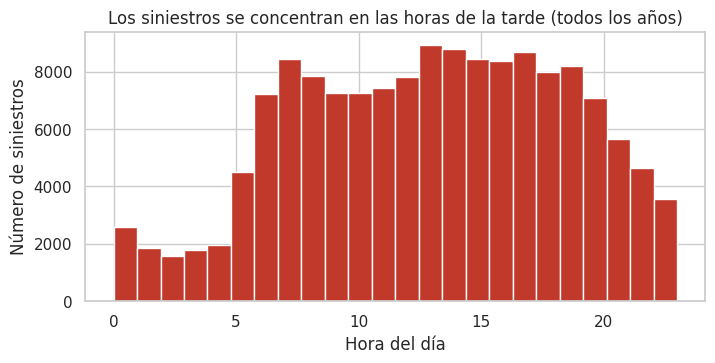

In [4]:
# Histograma inicial: ¿a qué horas ocurren los siniestros? (usando el texto original de la hora)
hora_inicial = pd.to_numeric(sin_raw["HORA_OCURRENCIA_ACC"].astype(str).str[:2], errors="coerce")
plt.figure(figsize=(8, 3.5))
plt.hist(hora_inicial.dropna(), bins=24, color="#c0392b", edgecolor="white")
plt.title("Los siniestros se concentran en las horas de la tarde (todos los años)")
plt.xlabel("Hora del día"); plt.ylabel("Número de siniestros"); plt.show()

### 1.3 Limpieza
Cada decisión se registra en una bitácora con la cantidad de registros afectados; al final se convierte en la tabla **problema → solución**.

In [5]:
bitacora = []
def reg(problema, solucion, n):
    bitacora.append({"problema": problema, "solución": solucion, "registros afectados": int(n)})

def norm(c):
    c = unicodedata.normalize("NFKD", str(c)).encode("ascii", "ignore").decode()
    return re.sub(r"[^a-z0-9]+", "_", c.lower()).strip("_")

def limpiar_texto(serie):
    s = serie.astype("string").str.strip().str.upper()
    s = s.map(lambda x: unicodedata.normalize("NFKD", x).encode("ascii", "ignore").decode() if pd.notna(x) else x)
    return s.str.replace(r"\s+", " ", regex=True)

s = sin_raw.copy()
s.columns = [norm(c) for c in s.columns]
necesarias = ["codigo_accidente", "fecha_ocurrencia_acc", "hora_ocurrencia_acc", "gravedad", "clase_acc", "localidad"]
falta = [c for c in necesarias if c not in s.columns]
if falta:
    raise KeyError(f"No encuentro estas columnas en siniestros.csv: {falta}. Columnas disponibles: {list(s.columns)}")

# 1. Textos: espacios, mayúsculas y tildes
for c in ["gravedad", "clase_acc", "localidad", "barrio", "municipio"]:
    if c in s.columns:
        s[c] = limpiar_texto(s[c])
reg("textos con espacios, mayúsculas o tildes inconsistentes", "estandarizados (sin espacios sobrantes, mayúsculas, sin tildes)", len(s))

# 2. Códigos como números y duplicados por clave del siniestro
s["codigo_accidente"] = pd.to_numeric(s["codigo_accidente"], errors="coerce")
n = s["codigo_accidente"].isna().sum()
s = s.dropna(subset=["codigo_accidente"])
reg("siniestros sin código válido", "eliminados", n)
n = s.duplicated(subset=["codigo_accidente"]).sum()
s = s.drop_duplicates(subset=["codigo_accidente"], keep="first")
reg("mismo código de siniestro repetido", "se conserva la primera aparición", n)
s["codigo_accidente"] = s["codigo_accidente"].astype("int64")

# Las tablas de víctimas y actores NO traen codigo_accidente: se enlazan por FORMULARIO
if "formulario" not in s.columns:
    raise KeyError("siniestros.csv no tiene la columna FORMULARIO, que es la llave para unir con las tablas de víctimas")
s["formulario"] = s["formulario"].astype("string").str.strip().str.upper()
n = s.duplicated(subset=["formulario"]).sum()
s = s.drop_duplicates(subset=["formulario"], keep="first")
reg("mismo formulario repetido en siniestros", "se conserva la primera aparición", n)

In [6]:
# 3. Hora: se toma del texto original (HH:MM:SS) y se deja solo hora y minuto
hora_txt = s["hora_ocurrencia_acc"].astype("string").str.strip()
hora_dt = pd.to_datetime(hora_txt, format="%H:%M:%S", errors="coerce")
if hora_dt.isna().mean() > 0.5:
    hora_dt = pd.to_datetime(hora_txt, format="mixed", errors="coerce")
s["hora_num"] = hora_dt.dt.hour
s["hora"] = hora_dt.dt.strftime("%H:%M")

# 4. Fecha: las fechas originales vienen en milisegundos Unix
def ms_a_fecha(serie, ajuste_horas=0):
    num = pd.to_numeric(serie, errors="coerce")
    if num.notna().mean() > 0.9:
        f = pd.to_datetime(num, unit="ms", errors="coerce")
    else:
        f = pd.to_datetime(serie, errors="coerce", format="mixed")
    return f + pd.Timedelta(hours=ajuste_horas)

# Zona horaria: probamos qué ajuste hace que la hora de FECHA_HORA_ACC coincida con la hora escrita en HORA_OCURRENCIA_ACC
mejor_ajuste, mejor_puntaje = 0, -1.0
if "fecha_hora_acc" in s.columns:
    for ajuste in (0, -5):
        f = ms_a_fecha(s["fecha_hora_acc"], ajuste)
        puntaje = (f.dt.hour == s["hora_num"]).mean()
        print(f"Ajuste {ajuste:+d} h → la hora coincide en {puntaje*100:.1f} % de los registros")
        if puntaje > mejor_puntaje:
            mejor_ajuste, mejor_puntaje = ajuste, puntaje

if mejor_puntaje >= 0.95:
    fecha_dt = ms_a_fecha(s["fecha_hora_acc"], mejor_ajuste).dt.normalize()
    fuente = f"FECHA_HORA_ACC con ajuste de {mejor_ajuste} h"
else:
    fecha_dt = ms_a_fecha(s["fecha_ocurrencia_acc"]).dt.normalize()
    fuente = "FECHA_OCURRENCIA_ACC sin ajuste"
    print("ATENCIÓN: la hora de FECHA_HORA_ACC no coincide con HORA_OCURRENCIA_ACC; se usa la fecha de FECHA_OCURRENCIA_ACC.")
print("Fecha tomada de:", fuente)

otra = ms_a_fecha(s["fecha_ocurrencia_acc"]).dt.normalize()
print(f"Coincidencia entre FECHA_OCURRENCIA_ACC y la fecha elegida: {(otra == fecha_dt).mean()*100:.1f} %")

s["fecha_dt"] = fecha_dt
n = s["fecha_dt"].isna().sum()
s = s.dropna(subset=["fecha_dt"])
reg("fechas inválidas o vacías", "eliminadas (sin fecha no sirve para el análisis)", n)
n = s["hora_num"].isna().sum()
s = s.dropna(subset=["hora_num"])
s["hora_num"] = s["hora_num"].astype(int)
reg("horas inválidas o vacías", "eliminadas", n)
reg("fecha en milisegundos Unix y hora con segundos", "convertidas a fecha (DD/MM/AAAA) y hora (HH:MM)", len(s))
print("Rango de fechas en todo el archivo:", s["fecha_dt"].min().date(), "→", s["fecha_dt"].max().date())

Ajuste +0 h → la hora coincide en 100.0 % de los registros
Ajuste -5 h → la hora coincide en 0.0 % de los registros
Fecha tomada de: FECHA_HORA_ACC con ajuste de 0 h
Coincidencia entre FECHA_OCURRENCIA_ACC y la fecha elegida: 100.0 %
Rango de fechas en todo el archivo: 2020-01-01 → 2026-10-30


In [7]:
# 5. Filtrar el periodo de análisis: 1 jun 2025 → 1 jun 2026 (ambos incluidos)
antes = len(s)
s = s[(s["fecha_dt"] >= pd.Timestamp(INICIO)) & (s["fecha_dt"] <= pd.Timestamp(FIN))].copy()
reg(f"registros fuera del periodo {INICIO} a {FIN}", "eliminados para trabajar un solo año", antes - len(s))
print(f"Siniestros en el periodo: {len(s):,}")
print(s.groupby(s["fecha_dt"].dt.to_period("M")).size())

# 6. Nulos geográficos: no se imputan con la moda, se marcan
for c in ["localidad", "barrio"]:
    if c in s.columns:
        n = s[c].isna().sum()
        s[c] = s[c].fillna("SIN DATO")
        if n: reg(f"{c} vacío", "marcado como SIN DATO (no se inventa el valor)", n)

# 7. Variables derivadas
DIAS = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
s["dia_semana"] = s["fecha_dt"].dt.dayofweek.map(dict(enumerate(DIAS)))
for c in ["latitud", "longitud"]:
    if c in s.columns:
        s[c] = pd.to_numeric(s[c], errors="coerce")

Siniestros en el periodo: 12,097
fecha_dt
2025-06     859
2025-07     954
2025-08    1079
2025-09    1133
2025-10    1060
2025-11     980
2025-12    1010
2026-01     828
2026-02     999
2026-03    1171
2026-04     950
2026-05    1052
2026-06      22
Freq: M, dtype: int64


#### Lesionados y fallecidos por siniestro
Las tablas de víctimas tienen **una fila por persona**, así que primero se cuentan por siniestro y luego se pasan a la tabla principal con un `map` (no un `merge`), que **no puede duplicar siniestros**.

In [8]:
CLAVE = "formulario"

def preparar_victimas(d, nombre):
    d = d.copy()
    d.columns = [norm(c) for c in d.columns]
    if CLAVE not in d.columns:
        raise KeyError(f"{nombre}: no hay columna {CLAVE}. Columnas: {list(d.columns)}")
    d[CLAVE] = d[CLAVE].astype("string").str.strip().str.upper()
    d = d.dropna(subset=[CLAVE])
    dup = 0
    if "codigo_accidentado" in d.columns:
        dup = d.duplicated(subset=["codigo_accidentado"]).sum()
        d = d.drop_duplicates(subset=["codigo_accidentado"])
    return d, dup

les, dup_les = preparar_victimas(les_raw, "victimas_lesionadas")
fal, dup_fal = preparar_victimas(fal_raw, "victimas_fallecidas")
act, _ = preparar_victimas(act_raw, "actores_viales")
print("Víctimas repetidas eliminadas → lesionadas:", dup_les, "| fallecidas:", dup_fal)

n_antes = len(s)
s["total_lesionados"] = s[CLAVE].map(les.groupby(CLAVE).size()).fillna(0).astype(int)
s["total_fallecidos"] = s[CLAVE].map(fal.groupby(CLAVE).size()).fillna(0).astype(int)
assert len(s) == n_antes, "La unión duplicó siniestros"
todos_formularios = set(sin_raw["FORMULARIO"].astype("string").str.strip().str.upper())
for nombre, d in [("lesionadas", les), ("fallecidas", fal), ("actores", act)]:
    print(f"Víctimas/actores de {nombre} cuyo formulario SÍ existe en siniestros.csv: {d[CLAVE].isin(todos_formularios).mean()*100:.1f} %")
reg("lesionados y fallecidos están en otras tablas (una fila por persona)", "contados por siniestro y agregados con map (sin duplicar siniestros)", len(s))

# Comprobaciones de coherencia
con_heridos_sin_les = ((s["gravedad"] == "CON HERIDOS") & (s["total_lesionados"] == 0)).sum()
solo_danos_con_les = ((s["gravedad"] == "SOLO DANOS") & (s["total_lesionados"] > 0)).sum()
con_muertos_sin_fal = ((s["gravedad"] == "CON MUERTOS") & (s["total_fallecidos"] == 0)).sum()
print("Comprobaciones de coherencia:")
print(" · CON HERIDOS sin lesionados registrados:", con_heridos_sin_les)
print(" · SOLO DANOS con lesionados registrados:", solo_danos_con_les)
print(" · CON MUERTOS sin fallecidos registrados:", con_muertos_sin_fal)
if con_heridos_sin_les:
    reg("siniestros CON HERIDOS sin víctimas en la tabla de lesionados", "se conservan con 0 lesionados y se documenta la inconsistencia", con_heridos_sin_les)

s["con_fallecidos"] = (s["gravedad"] == "CON MUERTOS").astype(int)
print("Siniestros con fallecidos en el periodo:", s["con_fallecidos"].sum())

Víctimas repetidas eliminadas → lesionadas: 0 | fallecidas: 0
Víctimas/actores de lesionadas cuyo formulario SÍ existe en siniestros.csv: 100.0 %
Víctimas/actores de fallecidas cuyo formulario SÍ existe en siniestros.csv: 100.0 %
Víctimas/actores de actores cuyo formulario SÍ existe en siniestros.csv: 100.0 %
Comprobaciones de coherencia:
 · CON HERIDOS sin lesionados registrados: 0
 · SOLO DANOS con lesionados registrados: 0
 · CON MUERTOS sin fallecidos registrados: 0
Siniestros con fallecidos en el periodo: 658


### 1.4 Quitar columnas innecesarias, guardar y resumir

In [9]:
df = s.rename(columns={"clase_acc": "clase_accidente"})
df["fecha"] = df["fecha_dt"].dt.strftime("%d/%m/%Y")      # solo día, mes y año

columnas_finales = ["codigo_accidente", "fecha", "hora", "dia_semana", "gravedad", "clase_accidente",
                    "localidad", "barrio", "latitud", "longitud",
                    "total_lesionados", "total_fallecidos", "con_fallecidos"]
columnas_finales = [c for c in columnas_finales if c in df.columns]
eliminadas = [c for c in s.columns if c not in df.columns or c not in columnas_finales]

df_export = df[columnas_finales].reset_index(drop=True)
df_export.to_csv(os.path.join(CARPETA_SALIDA, "siniestros_limpio.csv"), index=False, encoding="utf-8-sig")
reg("columnas innecesarias (ids internos, fechas en milisegundos, geometría duplicada, vía, etc.)",
    f"eliminadas; el CSV final conserva {len(columnas_finales)} columnas", len(sin_raw.columns) - len(columnas_finales))
print("Guardado:", os.path.join(CARPETA_SALIDA, "siniestros_limpio.csv"))
print("Columnas finales:", columnas_finales)

resumen = pd.DataFrame({
    "Antes (siniestros.csv)": [len(sin_raw), sin_raw.shape[1], int(sin_raw.isnull().sum().sum()), int(sin_raw.duplicated().sum())],
    "Después (limpio, 1 año)": [len(df_export), df_export.shape[1], int(df_export.isnull().sum().sum()), int(df_export.duplicated().sum())],
}, index=["Filas", "Columnas", "Nulos totales", "Duplicados"])
resumen

Guardado: datos/siniestros_limpio.csv
Columnas finales: ['codigo_accidente', 'fecha', 'hora', 'dia_semana', 'gravedad', 'clase_accidente', 'localidad', 'barrio', 'latitud', 'longitud', 'total_lesionados', 'total_fallecidos', 'con_fallecidos']


,Antes (siniestros.csv),"Después (limpio, 1 año)"
Filas,147923,12097
Columnas,23,13
Nulos totales,4411,0
Duplicados,0,0


**Tabla problema → solución** (la usarás en el notebook y en el video)

In [10]:
tabla_problemas = pd.DataFrame(bitacora)
tabla_problemas = tabla_problemas[tabla_problemas["registros afectados"] > 0].reset_index(drop=True)
tabla_problemas

,problema,solución,registros afectados
0,"textos con espacios, mayúsculas o tildes incon...","estandarizados (sin espacios sobrantes, mayúsc...",147923
1,fecha en milisegundos Unix y hora con segundos,convertidas a fecha (DD/MM/AAAA) y hora (HH:MM),147923
2,registros fuera del periodo 2025-06-01 a 2026-...,eliminados para trabajar un solo año,135826
3,localidad vacío,marcado como SIN DATO (no se inventa el valor),1
4,lesionados y fallecidos están en otras tablas ...,contados por siniestro y agregados con map (si...,12097
5,"columnas innecesarias (ids internos, fechas en...",eliminadas; el CSV final conserva 13 columnas,10


## Etapa 2 · Estadística descriptiva

### 2.1 Tendencia central y dispersión

In [11]:
def medidas(x):
    q1, q3 = x.quantile([0.25, 0.75])
    return pd.Series({
        "media": x.mean(), "mediana": x.median(), "moda": x.mode()[0],
        "mínimo": x.min(), "máximo": x.max(), "rango": x.max() - x.min(),
        "varianza": x.var(), "desv_estándar": x.std(),
        "cv_%": x.std() / x.mean() * 100 if x.mean() != 0 else np.nan,
        "Q1": q1, "Q3": q3, "IQR": q3 - q1, "asimetría": x.skew(),
    })

VAR = "total_lesionados"
tabla_medidas = pd.DataFrame({
    "lesionados por siniestro": medidas(df[VAR]),
    "hora (0-23)": medidas(df["hora_num"]),
}).round(2)
tabla_medidas

,lesionados por siniestro,hora (0-23)
media,1.60,12.57
mediana,1.00,13.00
moda,1.00,7.00
mínimo,0.00,0.00
máximo,41.00,23.00
rango,41.00,23.00
varianza,1.46,36.19
desv_estándar,1.21,6.02
cv_%,75.55,47.86
Q1,1.00,8.00


In [12]:
# Los siniestros SOLO DANOS tienen 0 lesionados por definición; mira también solo los que tuvieron heridos
con_heridos = df[df[VAR] > 0]
print(f"Siniestros con al menos un lesionado: {len(con_heridos):,} ({len(con_heridos)/len(df)*100:.1f} %)")
medidas(con_heridos[VAR]).round(2).to_frame("solo siniestros con lesionados")

Siniestros con al menos un lesionado: 10,922 (90.3 %)


,solo siniestros con lesionados
media,1.77
mediana,2.00
moda,1.00
mínimo,1.00
máximo,41.00
rango,40.00
varianza,1.31
desv_estándar,1.14
cv_%,64.67
Q1,1.00


In [13]:
m = tabla_medidas["lesionados por siniestro"]; h = tabla_medidas["hora (0-23)"]
print(f"• Un siniestro típico tiene {m['mediana']:.0f} lesionados (mediana); el promedio es {m['media']:.2f}.")
if m["media"] > m["mediana"]:
    print("• Media > mediana: asimetría positiva; pocos siniestros con muchas víctimas elevan el promedio.")
print(f"• Coeficiente de variación = {m['cv_%']:.0f} %:", "muy distintos entre sí." if m["cv_%"] > 50 else "relativamente parecidos.")
print(f"• Hora más frecuente (moda): {h['moda']:.0f}:00; mediana: {h['mediana']:.0f}:00.")

• Un siniestro típico tiene 1 lesionados (mediana); el promedio es 1.60.
• Media > mediana: asimetría positiva; pocos siniestros con muchas víctimas elevan el promedio.
• Coeficiente de variación = 76 %: muy distintos entre sí.
• Hora más frecuente (moda): 7:00; mediana: 13:00.


**Interpretación 2.1** *(la celda final "Textos listos para copiar" la redacta con tus cifras)*

### 2.2 Comparación entre variables

In [14]:
por_localidad = df["localidad"].value_counts()
tabla_loc = pd.DataFrame({"siniestros": por_localidad,
                          "%": (por_localidad / len(df) * 100).round(1),
                          "% acumulado": (por_localidad.cumsum() / len(df) * 100).round(1)})
print("Siniestros por localidad (top 10):"); display(tabla_loc.head(10))

por_dia = df["dia_semana"].value_counts().reindex(DIAS)
print("\nSiniestros por día de la semana:"); display(por_dia)

por_hora = df.groupby("hora_num").size()
print("\nHoras con más siniestros:"); display(por_hora.sort_values(ascending=False).head(5))

print("\nSiniestros por clase:"); display(df["clase_accidente"].value_counts())

Siniestros por localidad (top 10):


,siniestros,%,% acumulado
localidad,,,
KENNEDY,1610,13.3,13.3
SUBA,1091,9.0,22.3
ENGATIVA,1045,8.6,31.0
PUENTE ARANDA,1017,8.4,39.4
FONTIBON,815,6.7,46.1
BOSA,766,6.3,52.4
CIUDAD BOLIVAR,679,5.6,58.1
USAQUEN,642,5.3,63.4
RAFAEL URIBE URIBE,559,4.6,68.0



Siniestros por día de la semana:


,count
dia_semana,
Lunes,1515
Martes,1773
Miércoles,1814
Jueves,1757
Viernes,1919
Sábado,1874
Domingo,1445



Horas con más siniestros:


,0
hora_num,
7,803
17,737
6,695
18,678
8,670



Siniestros por clase:


,count
clase_accidente,
CHOQUE,8502
ATROPELLO,2540
CAIDA DE OCUPANTE,674
VOLCAMIENTO,287
OTRO,94


In [15]:
# Tipo de usuario vial: columna de la tabla actores_viales (se detecta sola; cámbiala si no es la correcta)
def buscar_col(d, *claves):
    for c in d.columns:
        if "codigo" in c or "formulario" in c or "objectid" in c:
            continue
        if any(k in c for k in claves):
            return c
    return None

print("Columnas de actores_viales:", list(act.columns))
ACTOR_COL = buscar_col(act, "actor", "condicion", "tipo_usuario", "usuario")
# ACTOR_COL = "nombre_de_columna"   # ← descomenta y cambia si la detectada no es la correcta
print("Columna usada para tipo de usuario vial:", ACTOR_COL)

act_periodo = act[act[CLAVE].isin(df[CLAVE])]
tabla_act = None
if ACTOR_COL:
    tabla_act = act_periodo[ACTOR_COL].astype("string").str.strip().str.upper().value_counts()
    print(f"\nPersonas involucradas por tipo de usuario vial (siniestros del periodo, n={len(act_periodo):,}):")
    display(pd.DataFrame({"personas": tabla_act.head(10), "%": (tabla_act.head(10) / tabla_act.sum() * 100).round(1)}))

# Fallecidos por tipo de usuario (para la hipótesis 2)
FAL_COL = buscar_col(fal, "actor", "condicion", "tipo_usuario", "usuario")
fal_periodo = fal[fal[CLAVE].isin(df[CLAVE])]
tabla_fal = None
if FAL_COL:
    tabla_fal = fal_periodo[FAL_COL].astype("string").str.strip().str.upper().value_counts()
    print(f"\nFallecidos por tipo de usuario (columna {FAL_COL}, n={len(fal_periodo):,}):")
    display(pd.DataFrame({"fallecidos": tabla_fal.head(10), "%": (tabla_fal.head(10) / tabla_fal.sum() * 100).round(1)}))

Columnas de actores_viales: ['objectid', 'formulario', 'codigo_accidentado', 'fecha_ocurrencia', 'codigo_victima', 'codigo_vehiculo', 'condicion', 'estado', 'muerte_posterior', 'fecha_posterior_muerte', 'genero', 'fecha_nacimiento', 'edad', 'codigo', 'condicion_a']
Columna usada para tipo de usuario vial: condicion

Personas involucradas por tipo de usuario vial (siniestros del periodo, n=29,051):


,personas,%
condicion,,
CONDUCTOR,10176,35.0
MOTOCICLISTA,9255,31.9
PASAJERO,5031,17.3
PEATON,2984,10.3
CICLISTA,1605,5.5



Fallecidos por tipo de usuario (columna condicion, n=676):


,fallecidos,%
condicion,,
MOTOCICLISTA,270,39.9
PEATON,254,37.6
CICLISTA,72,10.7
PASAJERO,67,9.9
CONDUCTOR,13,1.9


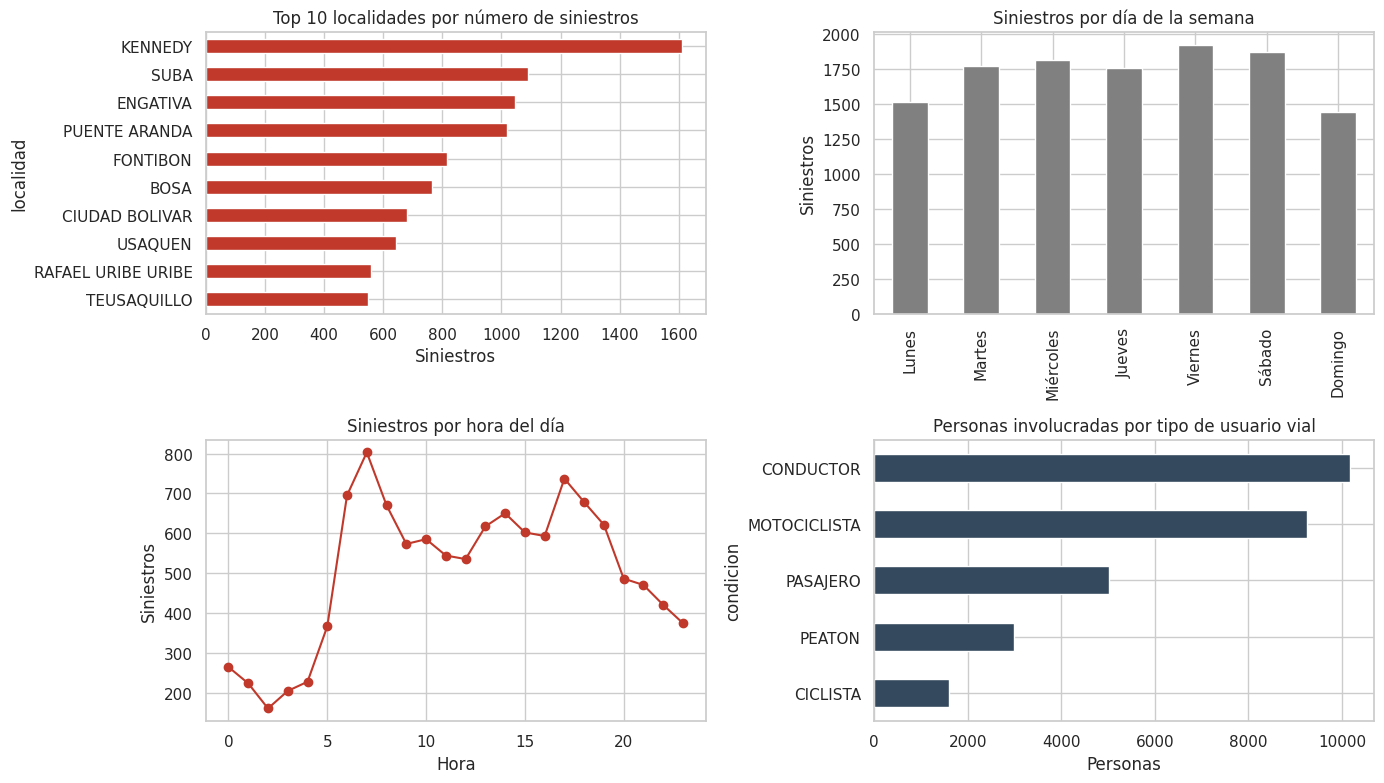

In [16]:
fig, ax = plt.subplots(2, 2, figsize=(14, 8))
tabla_loc.head(10)["siniestros"].sort_values().plot(kind="barh", ax=ax[0, 0], color="#c0392b")
ax[0, 0].set_title("Top 10 localidades por número de siniestros"); ax[0, 0].set_xlabel("Siniestros")
por_dia.plot(kind="bar", ax=ax[0, 1], color="grey")
ax[0, 1].set_title("Siniestros por día de la semana"); ax[0, 1].set_xlabel(""); ax[0, 1].set_ylabel("Siniestros")
por_hora.plot(kind="line", ax=ax[1, 0], color="#c0392b", marker="o")
ax[1, 0].set_title("Siniestros por hora del día"); ax[1, 0].set_xlabel("Hora"); ax[1, 0].set_ylabel("Siniestros")
if tabla_act is not None:
    tabla_act.head(8).sort_values().plot(kind="barh", ax=ax[1, 1], color="#34495e")
    ax[1, 1].set_title("Personas involucradas por tipo de usuario vial"); ax[1, 1].set_xlabel("Personas")
else:
    ax[1, 1].axis("off")
plt.tight_layout(); plt.show()

### 2.3 Valores atípicos (regla del IQR)

Límites IQR: [-0.50, 3.50]
Atípicos: 461 (3.81 % de los siniestros)
Máximo de lesionados en un siniestro: 41
Distribución de los atípicos:
total_lesionados
4     294
5      88
6      28
7      17
8       7
9       7
10      5
11      4
12      1
13      1
15      1
17      1
18      3
21      2
26      1
41      1
Name: count, dtype: int64


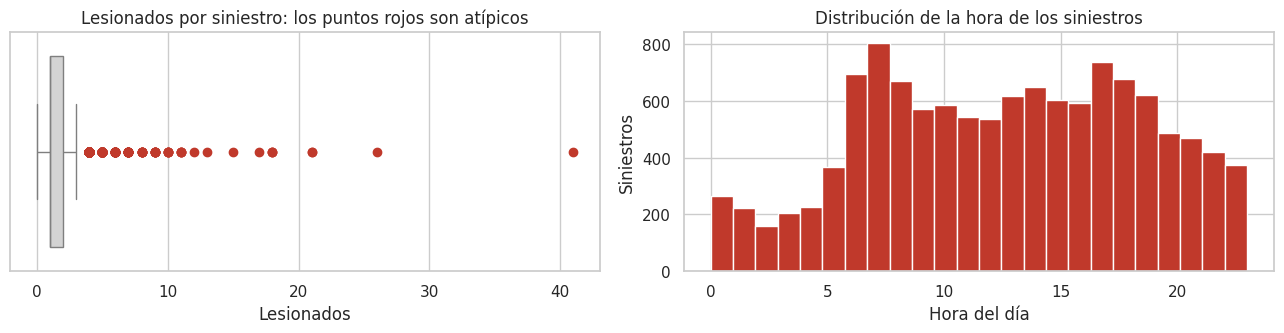

In [17]:
q1, q3 = df[VAR].quantile([0.25, 0.75])
iqr = q3 - q1
lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
atipicos = df[(df[VAR] < lim_inf) | (df[VAR] > lim_sup)]
print(f"Límites IQR: [{lim_inf:.2f}, {lim_sup:.2f}]")
print(f"Atípicos: {len(atipicos):,} ({len(atipicos)/len(df)*100:.2f} % de los siniestros)")
print(f"Máximo de lesionados en un siniestro: {df[VAR].max()}")
print("Distribución de los atípicos:"); print(atipicos[VAR].value_counts().sort_index())

fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
sns.boxplot(x=df[VAR], color="lightgrey", ax=ax[0], flierprops=dict(markerfacecolor="#c0392b", markeredgecolor="#c0392b"))
ax[0].set_title("Lesionados por siniestro: los puntos rojos son atípicos"); ax[0].set_xlabel("Lesionados")
ax[1].hist(df["hora_num"], bins=24, color="#c0392b", edgecolor="white")
ax[1].set_title("Distribución de la hora de los siniestros"); ax[1].set_xlabel("Hora del día"); ax[1].set_ylabel("Siniestros")
plt.tight_layout(); plt.show()

**Decisión sobre los atípicos:** antes de eliminar un atípico hay que decidir si es un error de digitación o un siniestro real y grave. Los reales se conservan porque son justo los casos que interesa estudiar. La celda final redacta la decisión con tus cifras; **revísala** y cámbiala si el máximo te parece imposible.

### 2.4 Hipótesis a partir de los valores

In [18]:
print("Siniestros con fallecidos:", df["con_fallecidos"].sum(), f"({df['con_fallecidos'].mean()*100:.2f} %)")

df["franja"] = np.where((df["hora_num"] >= 19) | (df["hora_num"] < 5), "Noche (19-04h)", "Día (05-18h)")
df["tipo_dia"] = np.where(df["dia_semana"].isin(["Sábado", "Domingo"]), "Fin de semana", "Entre semana")

print("\nH1 · % de siniestros con fallecidos por franja y tipo de día")
display((df.groupby("franja")["con_fallecidos"].mean() * 100).round(2).to_frame("% con fallecidos"))
display((df.groupby("tipo_dia")["con_fallecidos"].mean() * 100).round(2).to_frame("% con fallecidos"))

t = df.groupby("clase_accidente")["con_fallecidos"].agg(["size", "sum", "mean"])
t.columns = ["siniestros", "con_fallecidos", "% con fallecidos"]
t["% con fallecidos"] = (t["% con fallecidos"] * 100).round(2)
print("\nH2 · % con fallecidos por clase de siniestro")
display(t[t["siniestros"] >= 30].sort_values("% con fallecidos", ascending=False))

top5 = tabla_loc["%"].head(5).sum()
print(f"\nH3 · Las 5 localidades con más siniestros concentran el {top5:.1f} % del total")

Siniestros con fallecidos: 658 (5.44 %)

H1 · % de siniestros con fallecidos por franja y tipo de día


,% con fallecidos
franja,
Día (05-18h),4.53
Noche (19-04h),7.71


,% con fallecidos
tipo_dia,
Entre semana,5.31
Fin de semana,5.78



H2 · % con fallecidos por clase de siniestro


,siniestros,con_fallecidos,% con fallecidos
clase_accidente,,,
VOLCAMIENTO,287,52,18.12
ATROPELLO,2540,256,10.08
OTRO,94,4,4.26
CHOQUE,8502,340,4.00
CAIDA DE OCUPANTE,674,6,0.89



H3 · Las 5 localidades con más siniestros concentran el 46.0 % del total


## Textos listos para copiar y pegar
La celda siguiente redacta con tus cifras reales la conclusión de la Etapa 1, las interpretaciones de la Etapa 2 y las hipótesis. **Cópialos a celdas Markdown, léelos una vez y ajusta lo que no cuadre.** Tu docente puede preguntarte por tus resultados.

In [19]:
n0, n1 = len(sin_raw), len(df)
m = tabla_medidas["lesionados por siniestro"]; h = tabla_medidas["hora (0-23)"]
top_loc = tabla_loc.head(3)
top_dia = por_dia.idxmax(); hora_pico = por_hora.idxmax()
top3h = sorted(por_hora.sort_values(ascending=False).head(3).index.tolist())
p = df.groupby("franja")["con_fallecidos"].mean() * 100
q = df.groupby("tipo_dia")["con_fallecidos"].mean() * 100
cv_txt = "muy distintos entre sí" if m["cv_%"] > 50 else "relativamente parecidos"
sesgo = ("Como la media supera a la mediana, hay asimetría positiva: pocos siniestros con muchas víctimas elevan el promedio, por eso reportamos la mediana."
         if m["media"] > m["mediana"] else "La media y la mediana son parecidas, así que la distribución es bastante simétrica.")
mh = medidas(con_heridos[VAR])

print("**Conclusión de la Etapa 1**")
print(f"Partimos de {n0:,} siniestros (2020 a 2026) y {sin_raw.shape[1]} columnas en siniestros.csv. Documentamos {len(tabla_problemas)} problemas o decisiones "
      f"de limpieza (fechas en milisegundos, hora con segundos, textos, nulos geográficos, víctimas en otras tablas y columnas innecesarias) y los resolvimos como muestra la tabla problema → solución. "
      f"Trabajamos el periodo del 1 de junio de 2025 al 1 de junio de 2026: el dataset limpio quedó con {n1:,} siniestros y {df_export.shape[1]} columnas, guardado en datos/siniestros_limpio.csv.\n")

print(f"Nota: en este periodo {df['gravedad'].value_counts(normalize=True).get('CON HERIDOS', 0)*100:.0f} % de los siniestros son CON HERIDOS, {df['gravedad'].value_counts(normalize=True).get('SOLO DANOS', 0)*100:.0f} % SOLO DANOS y {df['con_fallecidos'].mean()*100:.1f} % CON MUERTOS.\n")
print("**Interpretación 2.1**")
print(f"- Tendencia central: un siniestro típico tiene {m['mediana']:.0f} lesionado(s) (mediana); el promedio es {m['media']:.2f} y la moda es {m['moda']:.0f}. {sesgo} "
      f"Si miramos solo los siniestros con heridos ({len(con_heridos)/n1*100:.0f} % del total), la mediana es {mh['mediana']:.0f} y el promedio {mh['media']:.2f}.")
print(f"- Dispersión: la desviación estándar es {m['desv_estándar']:.2f} y el coeficiente de variación es {m['cv_%']:.0f} %, lo que indica que los siniestros son {cv_txt}. El IQR es {m['IQR']:.2f}.")
print(f"- Hora: la hora más frecuente es las {h['moda']:.0f}:00 y la mediana las {h['mediana']:.0f}:00; la mitad central de los siniestros ocurre entre las {h['Q1']:.0f}:00 y las {h['Q3']:.0f}:00.\n")

print("**Interpretación 2.2**")
print(f"- Las 3 localidades con más siniestros son {', '.join(top_loc.index)} y juntas concentran el {top_loc['%'].sum():.1f} % del total.")
print(f"- El día con más siniestros es {top_dia} y la hora con más casos es las {hora_pico}:00 (las 3 horas críticas: {', '.join(str(x)+':00' for x in top3h)}).")
if tabla_act is not None:
    print(f"- Por tipo de usuario vial, el grupo con más personas involucradas es {tabla_act.index[0]} ({tabla_act.iloc[0]/tabla_act.sum()*100:.1f} %).")
print()

fila_max = df.loc[df[VAR].idxmax()]
aviso = (f" El máximo corresponde a un siniestro del {fila_max['fecha']} en {fila_max['localidad']} (clase {fila_max['clase_accidente']}); los datos no permiten confirmar si es un caso real o un error de digitación; conviene revisarlo antes de decidir.") if df[VAR].max() >= 15 else ""
print("**Decisión sobre atípicos (2.3)**")
print(f"Con la regla del IQR (límites {lim_inf:.2f} a {lim_sup:.2f}) hay {len(atipicos):,} atípicos ({len(atipicos)/n1*100:.2f} % de los siniestros); el máximo es {df[VAR].max()} lesionados. "
      f"Los conservamos porque corresponden a siniestros reales y graves, justo los que interesa estudiar.{aviso}\n")

print("**Hipótesis para la Etapa 3**")
pn, pd_ = p.get("Noche (19-04h)", float("nan")), p.get("Día (05-18h)", float("nan"))
pf, pe = q.get("Fin de semana", float("nan")), q.get("Entre semana", float("nan"))
txt_noche = (f"de noche es claramente mayor ({pn:.2f} % vs {pd_:.2f} % de día)" if pn - pd_ > 1
             else f"de noche y de día es parecida ({pn:.2f} % vs {pd_:.2f} %)")
txt_fin = (f"en fin de semana es mayor ({pf:.2f} % vs {pe:.2f} % entre semana)" if pf - pe > 1
           else f"entre fin de semana y entre semana casi no cambia ({pf:.2f} % vs {pe:.2f} %)")
print(f"1. La proporción de siniestros con fallecidos {txt_noche}, y {txt_fin}.")
if tabla_fal is not None:
    print(f"2. Los usuarios vulnerables (motociclistas, peatones, ciclistas) están sobrerrepresentados entre las víctimas fatales: el grupo con más fallecidos es {tabla_fal.index[0]} ({tabla_fal.iloc[0]/tabla_fal.sum()*100:.1f} % de los fallecidos).")
else:
    print("2. Los usuarios vulnerables (motociclistas, peatones, ciclistas) están sobrerrepresentados entre las víctimas fatales; revisa la tabla H2 por clase de siniestro.")
if top5 >= 50:
    print(f"3. Pocas localidades concentran la mayor parte de los siniestros: las 5 primeras suman el {top5:.1f} %.")
else:
    print(f"3. Los siniestros se concentran en pocas localidades: las 5 primeras suman el {top5:.1f} % del total (casi la mitad), con Kennedy a la cabeza.")
print("\n(Si alguna cifra contradice una hipótesis, reescribe esa hipótesis según lo que muestran los datos.)")

**Conclusión de la Etapa 1**
Partimos de 147,923 siniestros (2020 a 2026) y 23 columnas en siniestros.csv. Documentamos 6 problemas o decisiones de limpieza (fechas en milisegundos, hora con segundos, textos, nulos geográficos, víctimas en otras tablas y columnas innecesarias) y los resolvimos como muestra la tabla problema → solución. Trabajamos el periodo del 1 de junio de 2025 al 1 de junio de 2026: el dataset limpio quedó con 12,097 siniestros y 13 columnas, guardado en datos/siniestros_limpio.csv.

Nota: en este periodo 88 % de los siniestros son CON HERIDOS, 7 % SOLO DANOS y 5.4 % CON MUERTOS.

**Interpretación 2.1**
- Tendencia central: un siniestro típico tiene 1 lesionado(s) (mediana); el promedio es 1.60 y la moda es 1. Como la media supera a la mediana, hay asimetría positiva: pocos siniestros con muchas víctimas elevan el promedio, por eso reportamos la mediana. Si miramos solo los siniestros con heridos (90 % del total), la mediana es 2 y el promedio 1.77.
- Dispersión: la